# 최종 분석 — 쓰레기 이미지 12종 분류 (최종 모델 E9)

**최종 모델 = E9 단일 (결정 A)**: ImageNet ResNet18 (torchvision), layer4 + MLP 헤드(512→256→128→12, ReLU) 학습, 나머지 백본 동결, 입력 224px, degrade 증강(어둡게·흐림), train_mix 12,000장(클래스당 1,000).

- 이 노트북은 `01_coding/RESULT/`에 저장된 결과 파일만 읽는다. **재학습·TEST 재평가 없음** (TEST는 E9로 1회만 사용).
- 학습·평가 코드: `01_coding/notebooks/*.py` (`gc_lib.py` = 데이터셋·모델·학습 루프, `run_exp.py`·`overnight*.py` = 실험 실행, `final_test.py` = TEST 1회)
- 실행 방법: `01_coding/notebooks/` 폴더에서 열고 위에서부터 순서대로 실행

| 절 | 확인 항목 | 읽는 파일 |
|---|---|---|
| 0 | 최종 모델 구조·설정 | RESULT/experiments/history/E9_cfg.json |
| 1 | 실험 흐름 E1→E9 | RESULT/experiments/experiments.csv |
| 2 | 손실 곡선·과적합 | RESULT/experiments/history/E*.csv |
| 3 | 최종 TEST 혼동행렬·클래스별 정밀도/재현율 | RESULT/final_test/ |
| 4 | 검증셋 혼동행렬 (손상 사진 포함) | RESULT/ensemble/ensemble_preds.csv |
| 5 | 대안(확률 평균·스태킹) 비교와 결정 A | RESULT/ensemble/ensemble_compare.json |

In [1]:
# [셀 목적] 라이브러리·경로 불러오기 + 필요한 결과 파일이 모두 있는지 확인
# - gc_lib: 프로젝트 공용 모듈 (경로 상수, 클래스 목록, 모델 생성 함수)
# - 파일이 하나라도 없으면 어떤 파일이 빠졌는지 출력하고 멈춘다 (이후 셀이 엉뚱한 오류로 죽는 것 방지)
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gc_lib as G

plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 폰트 (Windows)
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
CLASSES = G.CLASSES
FINAL = "E9"  # 최종 모델 ID

need = [G.EXP_CSV, G.FINAL_DIR / "final_test.json", G.FINAL_DIR / "final_test_confusion.csv",
        G.FINAL_DIR / "final_test_ext_confusion.csv", G.ENS_DIR / "ensemble_preds.csv",
        G.ENS_DIR / "ensemble_compare.json", G.HISTORY / f"{FINAL}_cfg.json"] + [G.HISTORY / f"E{i}.csv" for i in range(1, 10)]
missing = [str(p) for p in need if not Path(p).exists()]
assert not missing, f"결과 파일 없음: {missing}"
print("결과 폴더:", G.RESULTS)
print("결과 파일", len(need), "개 확인")

결과 폴더: D:\데이터 분석\빅데이터_프로그래밍\01_coding\RESULT
결과 파일 16 개 확인


## 0. 최종 모델 구조와 학습 설정

In [2]:
# [셀 목적] E9 학습 설정(cfg)을 출력하고, 그 설정으로 만든 분류 헤드 구조와 학습 파라미터 수를 확인
# - 가중치(체크포인트)는 불러오지 않는다: 구조만 확인 (ImageNet 가중치는 torchvision 캐시에서 로드)
cfg = json.load(open(G.HISTORY / f"{FINAL}_cfg.json", encoding="utf-8"))
print(json.dumps({k: v for k, v in cfg.items() if k != "notes"}, ensure_ascii=False, indent=1))
model = G.model_from_cfg(cfg)
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in model.parameters())
print("\n분류 헤드:", model.fc)
print(f"학습 파라미터 {n_train:,} / 전체 {n_all:,} ({n_train / n_all:.1%}) — layer4 + 헤드만 학습")

{
 "seed": 42,
 "model": "resnet18",
 "img_size": 224,
 "freeze": "layer4",
 "optimizer": "adamw",
 "lr": 0.001,
 "weight_decay": 0.0001,
 "batch": 32,
 "epochs": 10,
 "patience": 3,
 "aug": [
  "degrade"
 ],
 "train_data": "mix",
 "max_per_class": 1000,
 "threads": 12,
 "num_workers": 0,
 "exp_id": "E9",
 "base_exp": "E8",
 "changed_var": "img_size",
 "value": "224",
 "hidden": [
  256,
  128
 ],
 "act": "relu"
}



분류 헤드: Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=12, bias=True)
)
학습 파라미터 8,559,500 / 전체 11,342,284 (75.5%) — layer4 + 헤드만 학습


## 1. 실험 흐름 E1 → E9
S3 = (val + val_ext + val_hard)/3. 채택 = 직전 최고 대비 +1%p 이상 & clothes·shoes val −3%p 이내. E9(224px)는 val_hard가 160px로 고정 생성돼 (val+val_ext)/2로 판정(사전 등록).

In [3]:
# [셀 목적] 실험 기록표(experiments.csv)에 val_hard 정확도를 붙여 S3와 train–val 차이를 계산해 표로 출력
# - 안전 확인: TEST(test_used=1)를 쓴 실험은 E9 하나뿐이어야 한다
exp = pd.read_csv(G.EXP_CSV)
exp["val_hard"] = [json.load(open(G.HISTORY / f"{e}_val_hard.json", encoding="utf-8"))["val_hard_acc"] for e in exp.exp_id]
exp["S3"] = ((exp.val_acc + exp.val_ext_acc + exp.val_hard) / 3).round(4)
exp["train_val_gap"] = (exp.train_acc - exp.val_acc).round(4)
cols = ["exp_id", "base_exp", "changed_var", "value", "img_size", "freeze", "aug", "train_acc", "val_acc",
        "val_ext_acc", "val_hard", "S3", "train_val_gap", "best_epoch", "epochs_run", "test_acc", "test_used"]
assert exp.test_used.fillna(0).sum() == 1 and exp.loc[exp.test_used == 1, "exp_id"].item() == FINAL, "TEST는 E9 1회만"
exp[cols]

,exp_id,base_exp,changed_var,value,img_size,freeze,aug,train_acc,val_acc,val_ext_acc,val_hard,S3,train_val_gap,best_epoch,epochs_run,test_acc,test_used
0,E1,NaN,baseline,kaggle<=1000/cls,160,backbone,none,0.9423,0.9317,0.388,0.6133,0.6443,0.0106,6,9,NaN,0
1,E2,E1,train_data,mix(train_mix.csv),160,backbone,none,0.8364,0.8956,0.724,0.6892,0.7696,-0.0592,3,6,NaN,0
2,E3,E2,aug,degrade,160,backbone,degrade,0.8362,0.8930,0.744,0.7150,0.7840,-0.0568,5,8,NaN,0
3,E4,E3,hidden,"1층(512→256, ReLU)",160,backbone,degrade,0.8952,0.9115,0.784,0.7633,0.8196,-0.0163,6,9,NaN,0
4,E5,E3,hidden,"2층(512→256→128, ReLU)",160,backbone,degrade,0.9119,0.9085,0.820,0.7683,0.8323,0.0034,8,10,NaN,0
5,E6,E5,act,gelu,160,backbone,degrade,0.9158,0.9162,0.790,0.7617,0.8226,-0.0004,7,10,NaN,0
6,E7,E5,aug,degrade_strong(밝기 0.15~1.0),160,backbone,degrade_strong,0.9046,0.9141,0.796,0.7667,0.8256,-0.0095,8,10,NaN,0
7,E8,E5,freeze,layer4,160,layer4,degrade,0.9488,0.9269,0.854,0.8292,0.8700,0.0219,6,9,NaN,0
8,E9,E8,img_size,224,224,layer4,degrade,0.9713,0.9493,0.890,0.8342,0.8912,0.0220,10,10,0.9394,1


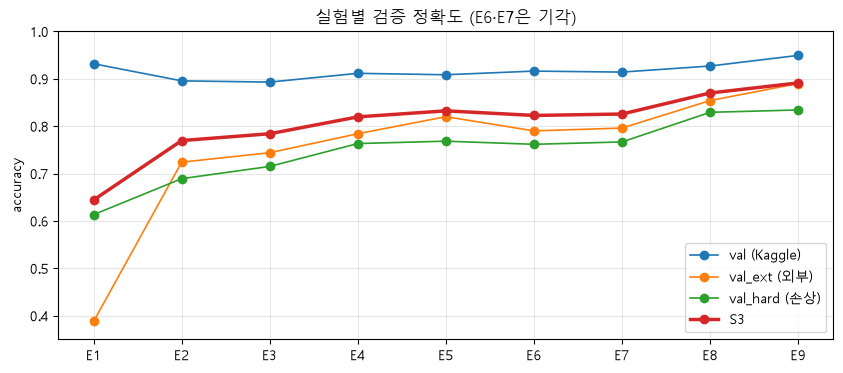

In [4]:
# [셀 목적] 실험별 검증 정확도 추이 그래프 (val·val_ext·val_hard·S3) — 어떤 변경이 성능을 올렸는지 한눈에 보기
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(exp))
for col, lab in [("val_acc", "val (Kaggle)"), ("val_ext_acc", "val_ext (외부)"), ("val_hard", "val_hard (손상)"), ("S3", "S3")]:
    ax.plot(x, exp[col], "-o", label=lab, lw=2.5 if col == "S3" else 1.2)
ax.set_xticks(x, exp.exp_id)
ax.set(ylim=(0.35, 1.0), ylabel="accuracy", title="실험별 검증 정확도 (E6·E7은 기각)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 2. 손실 곡선과 과적합 확인
점선 = train, 실선 = val. 과적합이면 train loss는 계속 내려가는데 val loss가 다시 올라가고, train·val 정확도 차이가 커진다.

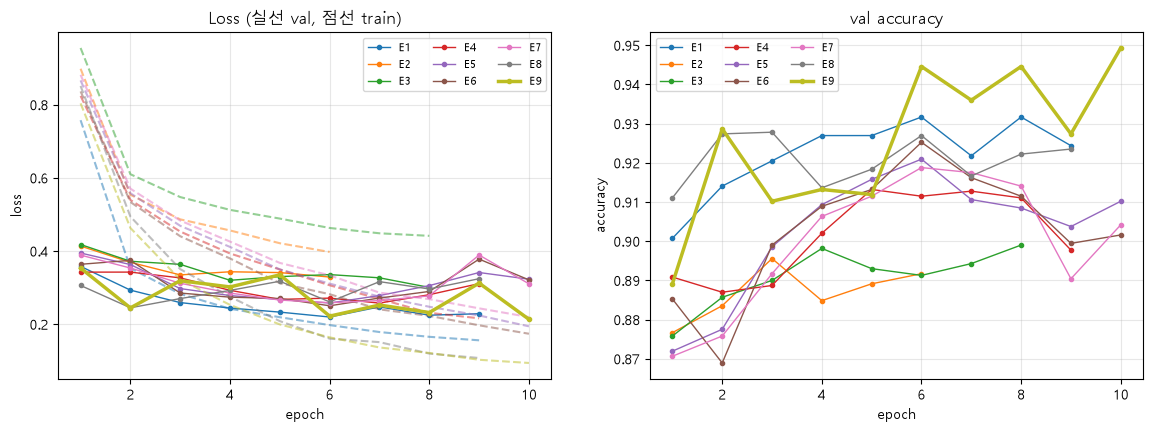

In [5]:
# [셀 목적] 전체 실험(E1~E9)의 epoch별 손실 곡선과 val 정확도 곡선을 겹쳐 그림 (E9는 굵은 선)
H = {e: pd.read_csv(G.HISTORY / f"{e}.csv") for e in exp.exp_id}  # 실험별 epoch 기록
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k, (e, h) in enumerate(H.items()):
    c = f"C{k}"
    ax[0].plot(h.epoch, h.train_loss, "--", color=c, alpha=0.5)
    ax[0].plot(h.epoch, h.val_loss, "-o", color=c, ms=3, label=e, lw=2.5 if e == FINAL else 1)
    ax[1].plot(h.epoch, h.val_acc, "-o", color=c, ms=3, label=e, lw=2.5 if e == FINAL else 1)
ax[0].set(title="Loss (실선 val, 점선 train)", xlabel="epoch", ylabel="loss")
ax[1].set(title="val accuracy", xlabel="epoch", ylabel="accuracy")
for a in ax:
    a.grid(alpha=0.3)
    a.legend(fontsize=8, ncol=3)
plt.show()

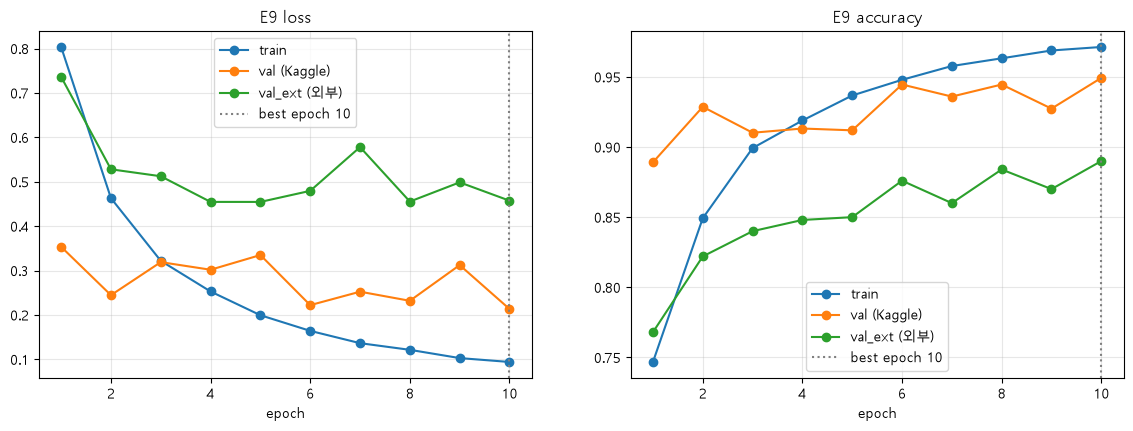

,epoch,train_loss,val_loss,val_ext_loss,train_acc,val_acc,val_ext_acc,acc_gap,loss_gap
0,1,0.8035,0.3534,0.7362,0.7468,0.8891,0.768,-0.1424,-0.4501
1,2,0.4630,0.2446,0.5280,0.8492,0.9287,0.822,-0.0794,-0.2184
2,3,0.3219,0.3189,0.5124,0.8992,0.9102,0.840,-0.0109,-0.0030
3,4,0.2528,0.3018,0.4546,0.9189,0.9132,0.848,0.0057,0.0490
4,5,0.1993,0.3349,0.4545,0.9368,0.9119,0.850,0.0248,0.1355
5,6,0.1641,0.2220,0.4795,0.9479,0.9446,0.876,0.0034,0.0579
6,7,0.1364,0.2523,0.5780,0.9578,0.9360,0.860,0.0218,0.1159
7,8,0.1214,0.2318,0.4554,0.9632,0.9446,0.884,0.0187,0.1104
8,9,0.1028,0.3123,0.4986,0.9688,0.9274,0.870,0.0415,0.2095
9,10,0.0940,0.2134,0.4574,0.9713,0.9493,0.890,0.0220,0.1194


In [6]:
# [셀 목적] 최종 모델 E9의 train / val / val_ext 손실·정확도 곡선 + epoch별 과적합 지표 표
# - acc_gap = train acc − val acc (클수록 과적합), loss_gap = val loss − train loss
h = H[FINAL]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(h.epoch, h.train_loss, "-o", label="train")
ax[0].plot(h.epoch, h.val_loss, "-o", label="val (Kaggle)")
ax[0].plot(h.epoch, h.val_ext_loss, "-o", label="val_ext (외부)")
ax[1].plot(h.epoch, h.train_acc, "-o", label="train")
ax[1].plot(h.epoch, h.val_acc, "-o", label="val (Kaggle)")
ax[1].plot(h.epoch, h.val_ext_acc, "-o", label="val_ext (외부)")
best = int(exp.loc[exp.exp_id == FINAL, "best_epoch"].item())
for a, t in zip(ax, ["E9 loss", "E9 accuracy"]):
    a.axvline(best, color="gray", ls=":", label=f"best epoch {best}")
    a.set(title=t, xlabel="epoch")
    a.grid(alpha=0.3)
    a.legend()
plt.show()
gap = h.assign(acc_gap=(h.train_acc - h.val_acc).round(4), loss_gap=(h.val_loss - h.train_loss).round(4))
gap[["epoch", "train_loss", "val_loss", "val_ext_loss", "train_acc", "val_acc", "val_ext_acc", "acc_gap", "loss_gap"]].round(4)

In [7]:
# [셀 목적] 과적합 판단용 요약 수치 출력: 마지막 epoch의 train–val 차이, val loss 최저 epoch, 검증 → TEST 점수 변화
last = gap.iloc[-1]
min_val_loss_ep = int(h.loc[h.val_loss.idxmin(), "epoch"])
print(f"E9 마지막 epoch: train acc {last.train_acc:.3f}, val acc {last.val_acc:.3f}, 차이 {last.acc_gap:+.3f}")
print(f"val loss 최저 epoch = {min_val_loss_ep} (마지막 epoch = {int(last.epoch)})")
t = json.load(open(G.FINAL_DIR / "final_test.json", encoding="utf-8"))
print(f"검증 → TEST: val {last.val_acc:.3f} → Kaggle test {t['test']['acc']:.3f}, "
      f"val_ext {last.val_ext_acc:.3f} → test_ext {t['test_ext']['acc']:.3f}")

E9 마지막 epoch: train acc 0.971, val acc 0.949, 차이 +0.022
val loss 최저 epoch = 10 (마지막 epoch = 10)
검증 → TEST: val 0.949 → Kaggle test 0.939, val_ext 0.890 → test_ext 0.908


**해석**: E9의 train–val 정확도 차이는 약 2%p로 작고, val loss는 마지막 epoch에서 가장 낮다. 따라서 뚜렷한 과적합은 없다. 검증 점수와 TEST 점수의 차이도 작아서 모델 선택 과정에서 생긴 편향(선택 편향)도 작다고 본다.

다만 E9는 10 epoch 상한에서 best가 나왔으므로 더 학습할 여지는 있다. 시간과 TEST 재사용 금지 때문에 추가 학습은 하지 않았다.

## 3. 최종 TEST 혼동행렬 (E9, 1회 평가)
Kaggle test 2,328장(12클래스) + 외부 test_ext 360장(9클래스: biological·clothes·shoes 없음). 정밀도 = 그 클래스로 예측한 것 중 맞은 비율(오탐이 적을수록 높음), 재현율 = 그 클래스 사진 중 맞힌 비율.

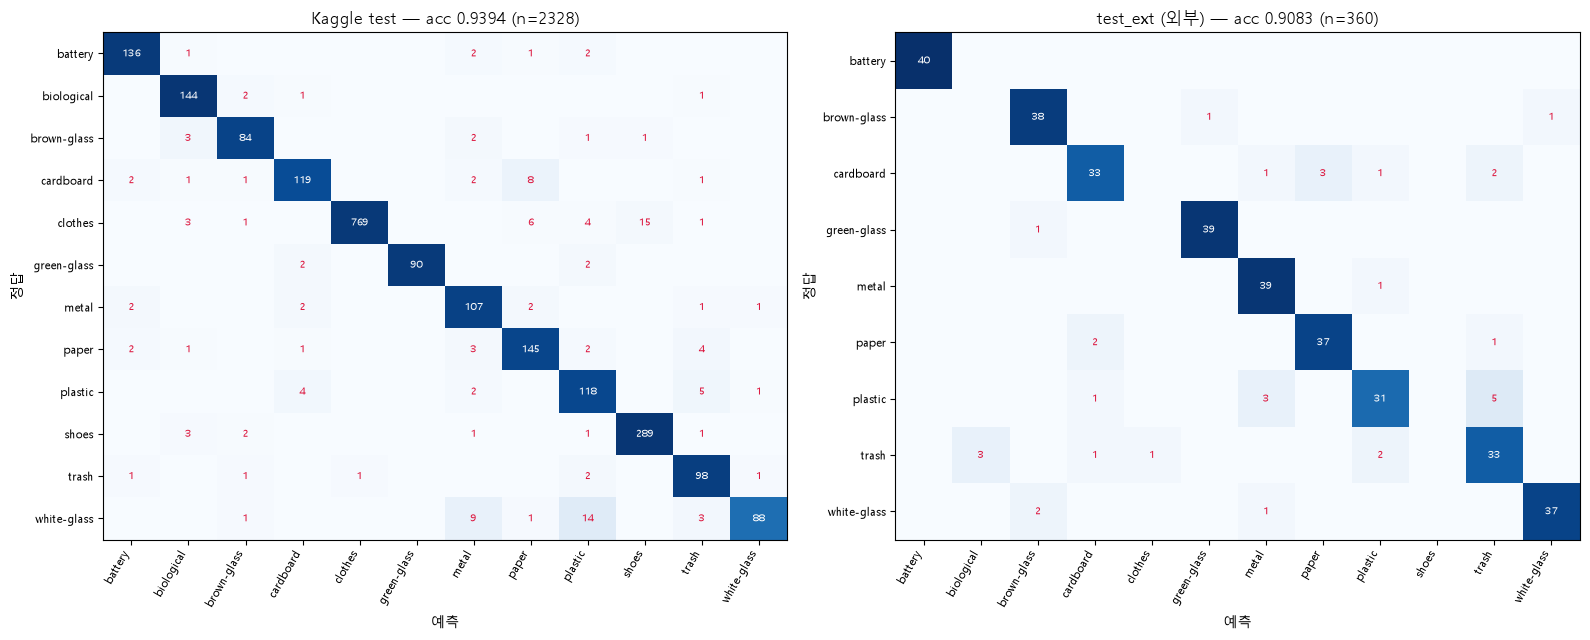

In [8]:
# [셀 목적] 혼동행렬 공용 함수 정의 + 최종 TEST 혼동행렬 2개(Kaggle test, test_ext)를 그림으로 출력
# - load_cm: 저장된 혼동행렬 CSV를 12클래스 순서로 정렬 (그 셋에 없는 정답 클래스 행은 제외)
# - class_report: 혼동행렬에서 클래스별 정밀도·재현율·F1·오탐(false_pos)·미탐(false_neg) 계산
# - plot_cm: 색 = 행(정답) 기준 비율, 숫자 = 장수, 빨간 숫자 = 오답
# - 안전 확인: 혼동행렬 합계·정확도가 final_test.json 값과 같은지 검사
def load_cm(path):
    cm = pd.read_csv(path, index_col=0)
    return cm.reindex(index=[c for c in CLASSES if c in cm.index], columns=CLASSES, fill_value=0)


def class_report(cm):
    tp = np.array([cm.loc[c, c] for c in cm.index])
    pred_tot = cm[cm.index].sum(axis=0).values  # 해당 클래스로 예측된 수 (이 셋에 있는 클래스만)
    true_tot = cm.sum(axis=1).values
    prec = np.divide(tp, pred_tot, out=np.full(len(tp), np.nan), where=pred_tot > 0)
    rec = tp / true_tot
    f1 = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0)
    r = pd.DataFrame(dict(n=true_tot, precision=prec, recall=rec, f1=f1, false_pos=pred_tot - tp, false_neg=true_tot - tp),
                     index=cm.index)
    return r.round(3)


def plot_cm(ax, cm, title):
    v = cm.values
    rate = v / v.sum(1, keepdims=True)
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if v[i, j]:
                ax.text(j, i, v[i, j], ha="center", va="center", fontsize=7,
                        color="white" if rate[i, j] > 0.5 else ("crimson" if cm.index[i] != cm.columns[j] else "black"))
    ax.set_xticks(range(v.shape[1]), cm.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(v.shape[0]), cm.index, fontsize=8)
    ax.set(title=title, xlabel="예측", ylabel="정답")


cm_test = load_cm(G.FINAL_DIR / "final_test_confusion.csv")
cm_ext = load_cm(G.FINAL_DIR / "final_test_ext_confusion.csv")
assert cm_test.values.sum() == t["test"]["n"] and cm_ext.values.sum() == t["test_ext"]["n"]
acc_test = np.trace(cm_test[cm_test.index].values) / cm_test.values.sum()
acc_ext = np.trace(cm_ext[cm_ext.index].values) / cm_ext.values.sum()
assert abs(acc_test - t["test"]["acc"]) < 1e-3 and abs(acc_ext - t["test_ext"]["acc"]) < 1e-3
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
plot_cm(ax[0], cm_test, f"Kaggle test — acc {acc_test:.4f} (n={cm_test.values.sum()})")
plot_cm(ax[1], cm_ext, f"test_ext (외부) — acc {acc_ext:.4f} (n={cm_ext.values.sum()})")
plt.tight_layout()
plt.show()

In [9]:
# [셀 목적] TEST 클래스별 정밀도·재현율·F1·오탐 수 표 (왼쪽 Kaggle test, 오른쪽 test_ext; test_ext에 없는 클래스는 NaN)
rep = pd.concat({"Kaggle test": class_report(cm_test), "test_ext": class_report(cm_ext)}, axis=1)
rep

Kaggle test                                             test_ext                                            
                      n precision recall     f1 false_pos false_neg        n precision recall     f1 false_pos false_neg
label                                                                                                                   
battery             142     0.951  0.958  0.954         7         6     40.0     1.000  1.000  1.000       0.0       0.0
biological          148     0.923  0.973  0.947        12         4      NaN       NaN    NaN    NaN       NaN       NaN
brown-glass          91     0.913  0.923  0.918         8         7     40.0     0.927  0.950  0.938       3.0       2.0
cardboard           134     0.922  0.888  0.905        10        15     40.0     0.892  0.825  0.857       4.0       7.0
clothes             799     0.999  0.962  0.980         1        30      NaN       NaN    NaN    NaN       NaN       NaN
green-glass          94     1.000  0.957  0.978         0         4     40.0     0.975  0.975  0.975       1.0       1.0
metal               115     0.836  0.930  0.881        21         8     40.0     0.886  0.975  0.929       5.0       1.0
paper               158     0.890  0.918  0.903        18        13     40.0     0.925  0.925  0.925       3.0       3.0
plastic             130     0.808  0.908  0.855        28        12     40.0     0.886  0.775  0.827       4.0       9.0
shoes               297     0.948  0.973  0.960        16         8      NaN       NaN    NaN    NaN       NaN       NaN
trash               104     0.852  0.942  0.895        17         6     40.0     0.805  0.825  0.815       8.0       7.0
white-glass         116     0.967  0.759  0.850         3        28     40.0     0.974  0.925  0.949       1.0       3.0

In [10]:
# [셀 목적] TEST에서 가장 많이 헷갈린 (정답 → 예측) 클래스 쌍 상위 8개
def top_confusions(cm, k=8):
    s = cm.stack()
    s = s[[a != b for a, b in s.index]]  # 대각선(정답) 제외
    s = s[s > 0].sort_values(ascending=False).head(k)
    return pd.DataFrame({"정답→예측": [f"{a}→{b}" for a, b in s.index], "장수": s.values})


pd.concat({"Kaggle test": top_confusions(cm_test), "test_ext": top_confusions(cm_ext)}, axis=1)

Kaggle test                     test_ext   
                 정답→예측  장수                    정답→예측 장수
0        clothes→shoes  15            plastic→trash  5
1  white-glass→plastic  14          cardboard→paper  3
2    white-glass→metal   9            plastic→metal  3
3      cardboard→paper   8         trash→biological  3
4        clothes→paper   6            trash→plastic  2
5        plastic→trash   5          paper→cardboard  2
6      clothes→plastic   4          cardboard→trash  2
7          paper→trash   4  white-glass→brown-glass  2

**해석 (TEST)**:
- Kaggle test에서 가장 약한 클래스는 white-glass다. 재현율이 낮고, 주로 투명 유리를 metal·plastic으로 혼동한다.
- test_ext는 RealWaste 출처(실사·지저분한 배경)에서 정확도가 낮다. plastic·cardboard·trash 사이의 혼동이 많다.
- 정밀도가 낮은 클래스는 다른 클래스 사진을 끌어오는 오탐이 많은 클래스다. 위 표의 false_pos 열에서 확인할 수 있다.

## 4. 검증셋 혼동행렬 (E9) — 손상·외부 사진에서 어디가 틀리는가
val_hard: Kaggle val 700 + val_ext 500장에 흐림·어둡게·빛번짐을 적용한 고정 셋(160px로 생성).

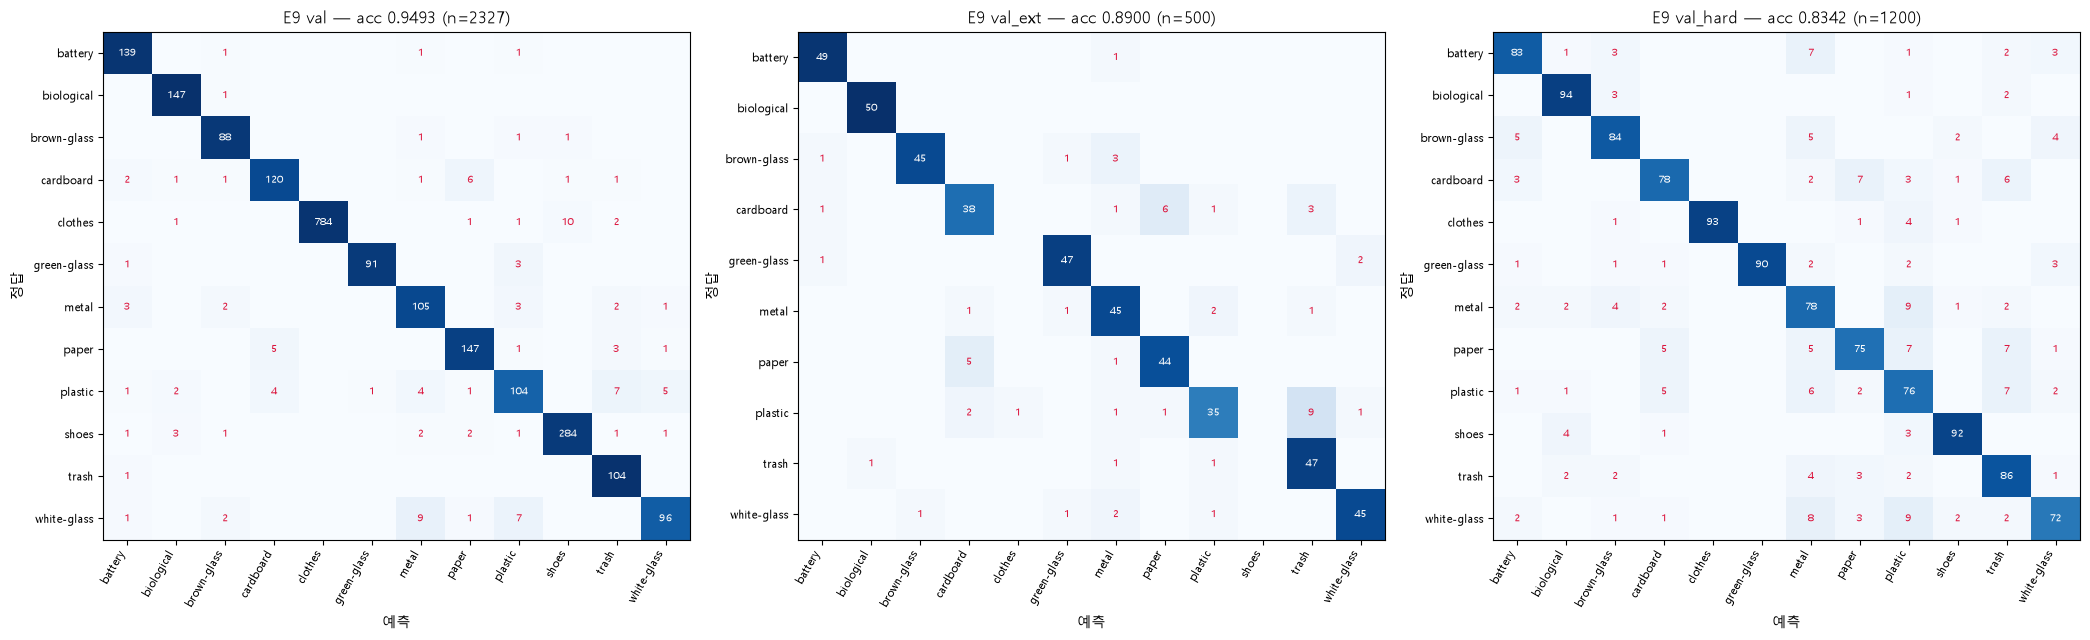

In [11]:
# [셀 목적] 저장된 이미지별 예측(ensemble_preds.csv)에서 E9 단일(single 열) 예측으로 검증셋 3개의 혼동행렬을 그림
P = pd.read_csv(G.ENS_DIR / "ensemble_preds.csv", keep_default_na=False)
assert set(P.set) == {"val", "val_ext", "val_hard"} and len(P) == 4027
fig, ax = plt.subplots(1, 3, figsize=(21, 6.5))
for a, k in zip(ax, ["val", "val_ext", "val_hard"]):
    s = P[P.set == k]
    cm = pd.crosstab(s.label, s.single).reindex(index=[c for c in CLASSES if c in set(s.label)], columns=CLASSES, fill_value=0)
    plot_cm(a, cm, f"E9 {k} — acc {(s.single == s.label).mean():.4f} (n={len(s)})")
plt.tight_layout()
plt.show()

In [12]:
# [셀 목적] val_hard 손상 종류별(흐림·어둡게·빛번짐) E9 정확도와 표본 수
vh = P[P.set == "val_hard"]
pd.DataFrame({
    "E9 정확도": vh.assign(ok=vh.single == vh.label).groupby("corruption").ok.mean().round(4),
    "n": vh.groupby("corruption").size(),
})

,E9 정확도,n
corruption,,
blur,0.7797,395
dark,0.8284,408
glare,0.8942,397


## 5. 대안 비교와 결정 A
같은 검증셋에서 E9 단일 / E9+E8 확률 평균 / E9+E8 스태킹(메타 학습 = meta_train 1,200장)의 오답을 비교했다. TEST는 사용하지 않았다.

In [13]:
# [셀 목적] 세 방식의 셋별 오답 수와 McNemar 검정(E9 단일 대비, 같은 사진에서 한쪽만 맞힌 수로 차이의 우연 여부 판단) 표
R = json.load(open(G.ENS_DIR / "ensemble_compare.json", encoding="utf-8"))
rows = []
for k, v in R["sets"].items():
    rows.append({"set": k, "n": v["n"], **{f"오답_{m}": e for m, e in v["errors"].items()},
                 "평균만 맞음/단일만 맞음": f"{v['mcnemar_vs_single']['avg']['only_other']}/{v['mcnemar_vs_single']['avg']['only_single']}",
                 "p(평균 vs 단일)": v["mcnemar_vs_single"]["avg"]["p"],
                 "p(스태킹 vs 단일)": v["mcnemar_vs_single"]["stack"]["p"]})
rows.append({"set": "합계", "n": len(P), **{f"오답_{m}": e for m, e in R["total_errors"].items()}})
pd.DataFrame(rows)

,set,n,오답_single,오답_avg,오답_stack,평균만 맞음/단일만 맞음,p(평균 vs 단일),p(스태킹 vs 단일)
0,val,2327,118,102,101,36/20,0.0440,0.0712
1,val_ext,500,55,54,65,12/11,1.0000,0.1325
2,val_hard,1200,199,166,183,62/29,0.0007,0.1598
3,합계,4027,372,322,349,NaN,NaN,NaN


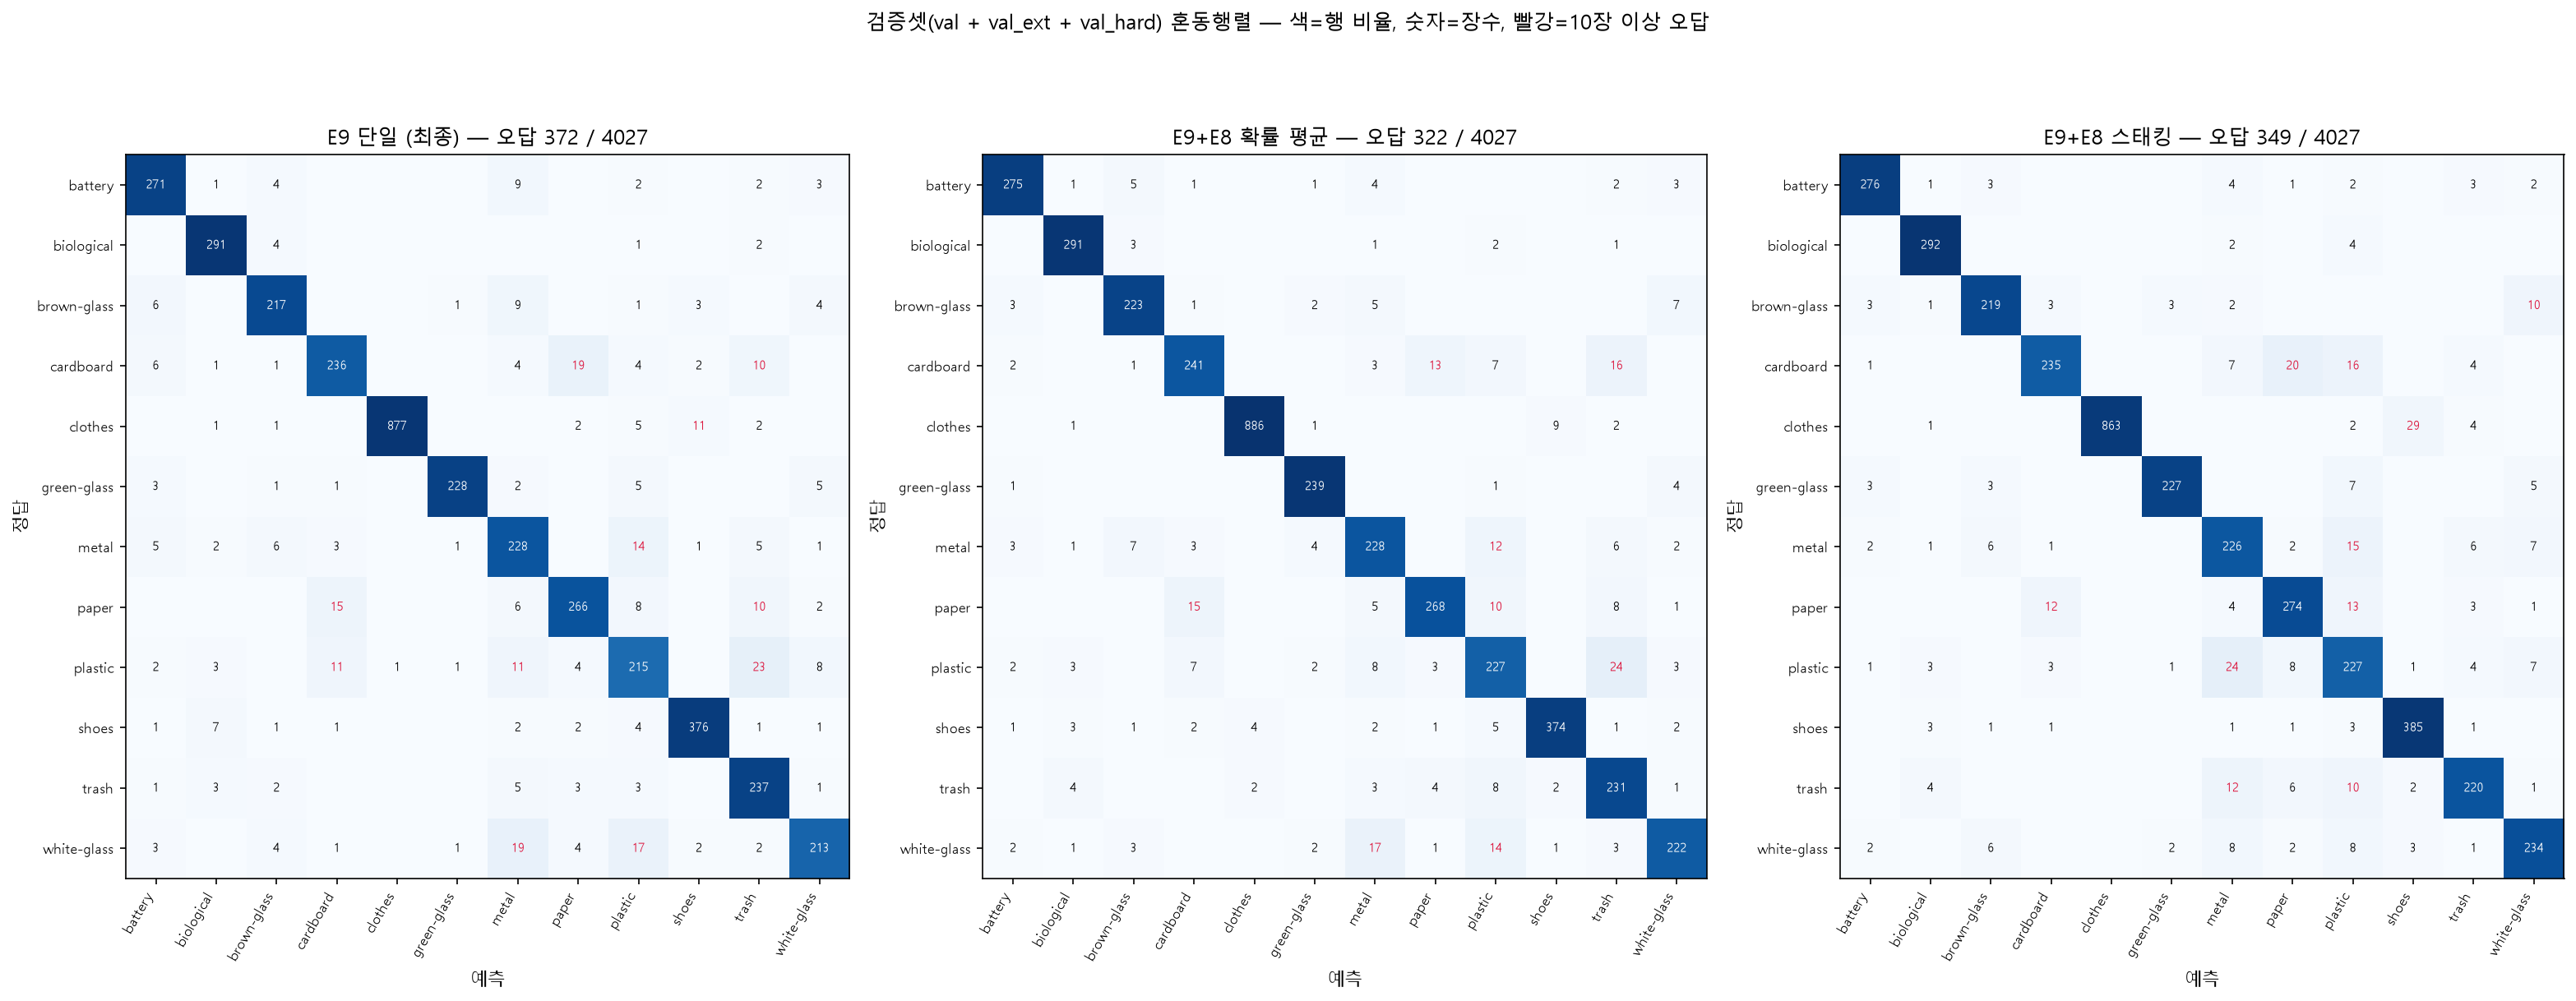

In [14]:
# [셀 목적] 세 방식의 검증셋 합계 혼동행렬 그림(ensemble_compare.py가 저장한 PNG) 표시
from IPython.display import Image, display
display(Image(filename=str(G.FIGURES / "ensemble_confusion.png"), width=1100))

**결정 A (최종 = E9 단일)의 근거**
1. 확률 평균은 검증셋 오답이 가장 적다(372 → 322). 하지만 이득이 깨끗한 Kaggle val(118 → 102)과 val_hard에 몰려 있다. val_hard는 160px로 만든 셋이라 160px 모델 E8에 유리하다. 외부 사진 val_ext에서는 55 → 54로 차이가 없다.
2. 사전 등록 기준인 (val+val_ext)/2 +1%p를 넘지 못했다(+0.4%p).
3. TEST는 E9로 이미 1회 사용했으므로, 다른 모델로 바꾸면 제출 모델의 TEST 점수를 보고할 수 없다.
4. 스태킹은 clothes→shoes(29건)와 trash 오답이 늘었다. meta_train(클래스당 100장)으로 학습한 메타 모델이 클래스 경계를 왜곡한 것으로 보여 가장 불안정하다.

## 6. 한계
- val_ext에는 clothes·shoes가 없고, test_ext에는 biological·clothes·shoes가 없다(외부 사진 부족).
- 작은 물체·넓은 배경, 오염·찌그러짐 조건은 태그가 없어 따로 측정하지 못했다. 측정한 조건은 흐림·어둡게·빛번짐뿐이다.
- 각 실험은 시드 42 한 번만 돌렸다. 1~2%p 차이는 노이즈 범위일 수 있다.